In [ ]:
#1 Import libraries required for data analysis and machine learning

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import functions for splitting data and evaluating models
from sklearn.model_selection import train_test_split

# Import functions for handling missing values
from sklearn.impute import SimpleImputer, KNNImputer

# Import functions for preprocessing data
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Import tools for building machine learning workflows
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Import joblib to save and load trained models
import joblib

# Display charts inside the notebook
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Scikit-Learn is a Python toolbox full of ready-made robot brains that look at table data, learn patterns, and guess answers automatically.
# often imported as sklearn
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
#2 Load the loan applicant dataset into a Pandas DataFrame

df = pd.read_csv("synthetic_loan_applicants_week2.csv")

# Display the first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("Dataset columns:")
print(df.columns.tolist())

First 5 rows of the dataset:


,applicant_id,application_date,age,annual_income,loan_amount,loan_term_months,credit_score,existing_debt,monthly_expenses,employment_type,education_level,home_ownership,loan_purpose,default
0,APP0001,2024-09-23,25.0,76567.0,21877,36,744.0,27669.0,4292.0,Salaried,Graduate,Rent,Personal,0
1,APP0002,2025-02-15,55.0,79738.0,33145,36,740.0,21079.0,3758.0,Salaried,Graduate,Mortgage,Home improvement,0
2,APP0003,2024-05-23,50.0,70792.0,33719,36,753.0,16642.0,4051.0,Salaried,Graduate,Mortgage,Education,0
3,APP0004,2024-03-22,40.0,31469.0,9901,24,727.0,1244.0,1327.0,Salaried,Diploma,Mortgage,Education,0
4,APP0005,2023-12-28,40.0,20456.0,16150,60,674.0,4077.0,853.0,Salaried,High School,Own,Home improvement,1


Dataset shape: (800, 14)
Dataset columns:
['applicant_id', 'application_date', 'age', 'annual_income', 'loan_amount', 'loan_term_months', 'credit_score', 'existing_debt', 'monthly_expenses', 'employment_type', 'education_level', 'home_ownership', 'loan_purpose', 'default']


In [6]:
#3 Check the number of missing values in each column

print("Missing values in each column:")
print(df.isnull().sum())

# Check the data type of each column
print("\nData types of each column:")
print(df.dtypes)

# Get a summary of numerical columns
print("\nStatistical summary:")
display(df.describe())

Missing values in each column:
applicant_id         0
application_date     0
age                 36
annual_income       19
loan_amount          0
loan_term_months     0
credit_score        27
existing_debt       21
monthly_expenses    25
employment_type     20
education_level     13
home_ownership      23
loan_purpose        13
default              0
dtype: int64

Data types of each column:
applicant_id            str
application_date        str
age                 float64
annual_income       float64
loan_amount           int64
loan_term_months      int64
credit_score        float64
existing_debt       float64
monthly_expenses    float64
employment_type         str
education_level         str
home_ownership          str
loan_purpose            str
default               int64
dtype: object

Statistical summary:


,age,annual_income,loan_amount,loan_term_months,credit_score,existing_debt,monthly_expenses,default
count,764.000000,781.000000,800.000000,800.000000,773.000000,779.000000,775.000000,800.000000
mean,43.333770,67593.096031,25320.953750,40.080000,692.857697,15198.709884,2640.014194,0.305000
std,12.971988,32716.004000,19308.150084,14.788745,62.832559,11202.229310,1591.941740,0.460695
min,21.000000,18000.000000,3000.000000,12.000000,511.000000,566.000000,354.000000,0.000000
25%,32.000000,44555.000000,11605.500000,36.000000,648.000000,6577.500000,1471.000000,0.000000
50%,43.000000,61959.000000,19758.000000,36.000000,693.000000,12532.000000,2306.000000,0.000000
75%,55.000000,81886.000000,33457.250000,48.000000,738.000000,21420.000000,3392.500000,1.000000
max,65.000000,250000.000000,120000.000000,60.000000,850.000000,59312.000000,11476.000000,1.000000


In [ ]:
#4 Select numerical columns for predicting loan default
# We exclude applicant_id, application_date and loan_amount
# because they are not needed for this classification task.

X = df[
    [
        "age",
        "annual_income",
        "loan_term_months",
        "credit_score",
        "existing_debt",
        "monthly_expenses"
    ]
]

# Select the target column (0 = No default, 1 = Default)
y = df["default"]

# First split: 60% training data and 40% remaining data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Second split: divide the remaining 40% equally
# This gives us 20% validation and 20% testing data.

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display the number of records in each set
print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

print("\nData splitting completed!")

Training data: (480, 6)
Validation data: (160, 6)
Testing data: (160, 6)

Data splitting completed!


In [ ]:
#5 Import Decision Tree and accuracy calculation tools
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Store the different tree depths we want to test
depth_values = [1, 3, 5, 10, None]

# Create empty lists to store accuracy results
train_accuracies = []
val_accuracies = []

# Train one Decision Tree for each depth
for depth in depth_values:

    # Create the Decision Tree model
    tree_model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    # Train the model using training data
    tree_model.fit(X_train, y_train)

    # Predict results for training data
    train_predictions = tree_model.predict(X_train)

    # Predict results for validation data
    val_predictions = tree_model.predict(X_val)

    # Calculate training accuracy
    train_accuracy = accuracy_score(
        y_train, train_predictions
    )

    # Calculate validation accuracy
    val_accuracy = accuracy_score(
        y_val, val_predictions
    )

    # Store the accuracy results
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    # Print results for each tree depth
    print(
        f"Depth: {depth} | "
        f"Train Accuracy: {train_accuracy:.2f} | "
        f"Validation Accuracy: {val_accuracy:.2f}"
    )

Depth: 1 | Train Accuracy: 0.70 | Validation Accuracy: 0.69
Depth: 3 | Train Accuracy: 0.72 | Validation Accuracy: 0.69
Depth: 5 | Train Accuracy: 0.76 | Validation Accuracy: 0.69
Depth: 10 | Train Accuracy: 0.90 | Validation Accuracy: 0.61
Depth: None | Train Accuracy: 1.00 | Validation Accuracy: 0.64


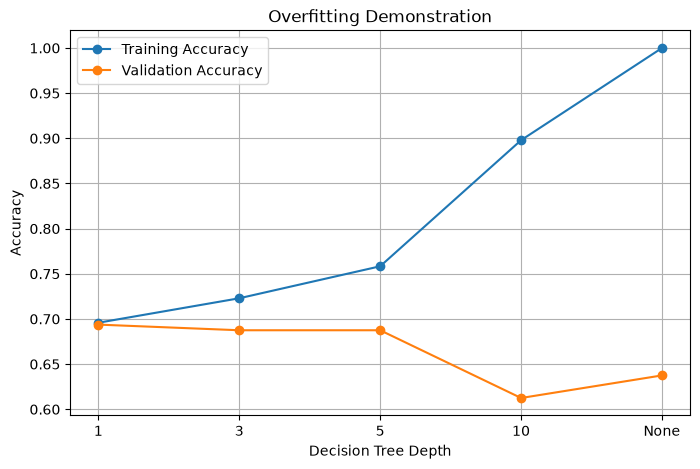

In [ ]:
#6 Plot training and validation accuracy for different tree depths

plt.figure(figsize=(8, 5))

# Plot training accuracy
plt.plot(range(len(depth_values)), train_accuracies,
         marker="o", label="Training Accuracy")

# Plot validation accuracy
plt.plot(range(len(depth_values)), val_accuracies,
         marker="o", label="Validation Accuracy")

# Add labels and title
plt.xticks(range(len(depth_values)), ["1", "3", "5", "10", "None"])
plt.xlabel("Decision Tree Depth")
plt.ylabel("Accuracy")
plt.title("Overfitting Demonstration")

# Show legend and graph
plt.legend()
plt.grid(True)
plt.show()

In [10]:
#7 Import Logistic Regression and cross-validation tools
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

# Create a pipeline with imputation and Logistic Regression
logistic_model = make_pipeline(
    SimpleImputer(strategy="median"),
    LogisticRegression(max_iter=1000)
)

# Perform 5-fold cross-validation
cv_scores = cross_val_score(
    logistic_model, X_train, y_train, cv=5, scoring="accuracy"
)

# Display individual scores
print("Cross-validation scores:", cv_scores)

# Display mean and standard deviation
print("Mean accuracy:", round(cv_scores.mean(), 3))
print("Standard deviation:", round(cv_scores.std(), 3))

Cross-validation scores: [0.66666667 0.69791667 0.69791667 0.71875    0.73958333]
Mean accuracy: 0.704
Standard deviation: 0.024


In [ ]:
#8 Import the required tools
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# INCORRECT: Scale the complete dataset before splitting
wrong_scaler = StandardScaler()
X_scaled_wrong = wrong_scaler.fit_transform(X)

# Split the already-scaled data
X_train_wrong, X_val_wrong, y_train_wrong, y_val_wrong = train_test_split(
    X_scaled_wrong, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Incorrect scaling completed.")

# CORRECT: Split the original data first
X_train_correct, X_val_correct, y_train_correct, y_val_correct = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit the scaler only on training data
correct_scaler = StandardScaler()
X_train_scaled_correct = correct_scaler.fit_transform(X_train_correct)

# Use the same scaler to transform validation data
X_val_scaled_correct = correct_scaler.transform(X_val_correct)

print("Correct scaling completed.")

Incorrect scaling completed.
Correct scaling completed.


Data Leakage — 4-line explanation
1. Incorrect scaling happens when we fit the scaler using the entire dataset before splitting.
2. This allows information from validation data to influence the training process.
3. Correct scaling means splitting the data first and fitting the scaler only on training data.
4. We then use the same fitted scaler to transform validation data, preventing data leakage.

In [ ]:
#9 Identify the type of Machine Learning problem

print("1. Spam detection: Supervised Learning")
print("2. Customer segmentation: Unsupervised Learning")
print("3. House price prediction: Supervised Learning")
print("4. Anomaly detection: Unsupervised Learning")

1. Spam detection: Supervised Learning
2. Customer segmentation: Unsupervised Learning
3. House price prediction: Supervised Learning
4. Anomaly detection: Unsupervised Learning


In [ ]:
#10 Seven steps of a Machine Learning workflow(task 1 complete)

workflow_steps = [
    "1. Define the problem",
    "2. Collect the data",
    "3. Clean and prepare the data",
    "4. Explore and understand the data",
    "5. Train the Machine Learning model",
    "6. Evaluate the model",
    "7. Deploy and monitor the model"
]

# Display all seven steps
for step in workflow_steps:
    print(step)

1. Define the problem
2. Collect the data
3. Clean and prepare the data
4. Explore and understand the data
5. Train the Machine Learning model
6. Evaluate the model
7. Deploy and monitor the model


In [ ]:
#11 Identify numerical columns
numeric_columns = [
    "age",
    "annual_income",
    "loan_amount",
    "loan_term_months",
    "credit_score",
    "existing_debt",
    "monthly_expenses"
]

# Identify categorical columns
categorical_columns = [
    "employment_type",
    "education_level",
    "home_ownership",
    "loan_purpose"
]

# Create a copy so the original dataset remains unchanged
df_imputed = df.copy()

# Fill missing numerical values using the median
numeric_imputer = SimpleImputer(strategy="median")
df_imputed[numeric_columns] = numeric_imputer.fit_transform(
    df_imputed[numeric_columns]
)

# Fill missing categorical values using the most frequent value
categorical_imputer = SimpleImputer(strategy="most_frequent")
df_imputed[categorical_columns] = categorical_imputer.fit_transform(
    df_imputed[categorical_columns]
)

# Check missing values after imputation
print("Missing values after imputation:")
print(df_imputed[numeric_columns + categorical_columns].isnull().sum())

print("\nMissing value handling completed!")

Missing values after imputation:
age                 0
annual_income       0
loan_amount         0
loan_term_months    0
credit_score        0
existing_debt       0
monthly_expenses    0
employment_type     0
education_level     0
home_ownership      0
loan_purpose        0
dtype: int64

Missing value handling completed!


In [15]:
#12 Import KNNImputer
from sklearn.impute import KNNImputer

# Create a copy of the original numerical data
df_knn = df[numeric_columns].copy()

# Create the KNN imputer with 5 neighbours
knn_imputer = KNNImputer(n_neighbors=5)

# Fill missing numerical values
df_knn_imputed = knn_imputer.fit_transform(df_knn)

# Convert the result back into a DataFrame
df_knn_imputed = pd.DataFrame(
    df_knn_imputed,
    columns=numeric_columns
)

# Check missing values
print("Missing values after KNN imputation:")
print(df_knn_imputed.isnull().sum())

print("\nKNN imputation completed!")

Missing values after KNN imputation:
age                 0
annual_income       0
loan_amount         0
loan_term_months    0
credit_score        0
existing_debt       0
monthly_expenses    0
dtype: int64

KNN imputation completed!


In [16]:
#13 Import OneHotEncoder
from sklearn.preprocessing import OneHotEncoder

# Create OneHotEncoder
onehot_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# Encode categorical columns
encoded_data = onehot_encoder.fit_transform(
    df_imputed[categorical_columns]
)

# Convert encoded data into a DataFrame
encoded_df = pd.DataFrame(
    encoded_data,
    columns=onehot_encoder.get_feature_names_out(categorical_columns)
)

# Display the first five rows
print("OneHotEncoded data:")
print(encoded_df.head())

print("\nEncoded shape:", encoded_df.shape)

OneHotEncoded data:
   employment_type_Business owner  employment_type_Contract  \
0                             0.0                       0.0   
1                             0.0                       0.0   
2                             0.0                       0.0   
3                             0.0                       0.0   
4                             0.0                       0.0   

   employment_type_Salaried  employment_type_Self-employed  \
0                       1.0                            0.0   
1                       1.0                            0.0   
2                       1.0                            0.0   
3                       1.0                            0.0   
4                       1.0                            0.0   

   education_level_Diploma  education_level_Graduate  \
0                      0.0                       1.0   
1                      0.0                       1.0   
2                      0.0                       1.0   
3   

In [ ]:
#14 Import OrdinalEncoder
from sklearn.preprocessing import OrdinalEncoder

# Define the correct education order
education_order = [
    ["High School", "Diploma", "Graduate", "Postgraduate"]
]

# Create OrdinalEncoder
ordinal_encoder = OrdinalEncoder(
    categories=education_order,
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

# Encode education level
df_imputed["education_level_encoded"] = ordinal_encoder.fit_transform(
    df_imputed[["education_level"]]
)

# Display original and encoded values
print(df_imputed[
    ["education_level", "education_level_encoded"]
].head(10))

  education_level  education_level_encoded
0        Graduate                      2.0
1        Graduate                      2.0
2        Graduate                      2.0
3         Diploma                      1.0
4     High School                      0.0
5        Graduate                      2.0
6     High School                      0.0
7    Postgraduate                      3.0
8        Graduate                      2.0
9        Graduate                      2.0


In [18]:
#15 Create a copy of the imputed dataset
df_features = df_imputed.copy()

# Convert application_date into datetime format
df_features["application_date"] = pd.to_datetime(
    df_features["application_date"]
)

# Feature 1: Extract application year
df_features["application_year"] = (
    df_features["application_date"].dt.year
)

# Feature 2: Calculate income-to-loan ratio
df_features["income_to_loan_ratio"] = (
    df_features["annual_income"] / df_features["loan_amount"]
)

# Feature 3: Apply log transformation to annual income
df_features["log_income"] = np.log1p(
    df_features["annual_income"]
)

# Display the new features
print(df_features[
    ["application_year", "income_to_loan_ratio", "log_income"]
].head())

print("\nFeature engineering completed!")

   application_year  income_to_loan_ratio  log_income
0              2024              3.499886   11.245935
1              2025              2.405732   11.286514
2              2024              2.099469   11.167515
3              2024              3.178366   10.356790
4              2023              1.266625    9.926080

Feature engineering completed!


In [19]:
#16 Select the input columns for our model
numeric_features = [
    "age",
    "annual_income",
    "loan_term_months",
    "credit_score",
    "existing_debt",
    "monthly_expenses",
    "application_year",
    "income_to_loan_ratio",
    "log_income"
]

categorical_features = [
    "employment_type",
    "home_ownership",
    "loan_purpose"
]

# Select the target column we want to predict
X = df_features[
    numeric_features + categorical_features
]

y = df_features["default"]

# Display the data shape
print("Input data shape:", X.shape)
print("Target data shape:", y.shape)

print("\nPipeline data prepared!")

Input data shape: (800, 12)
Target data shape: (800,)

Pipeline data prepared!


In [20]:
#17 Create a pipeline for numerical columns
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Create a pipeline for categorical columns
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Display confirmation
print("Numerical pipeline created!")
print("Categorical pipeline created!")
print("Preprocessing pipeline created!")

Numerical pipeline created!
Categorical pipeline created!
Preprocessing pipeline created!


In [21]:
# 18 Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the complete pipeline
full_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

# Display confirmation
print("Complete Machine Learning pipeline created!")

Complete Machine Learning pipeline created!


In [22]:
#19 Import train_test_split
from sklearn.model_selection import train_test_split

# First split: 60% training and 40% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Second split: Divide remaining data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display the data sizes
print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Training data: (480, 12)
Validation data: (160, 12)
Testing data: (160, 12)


In [23]:
#20 Start with the original dataset
df_raw = df.copy()

# Convert application date into datetime format
df_raw["application_date"] = pd.to_datetime(
    df_raw["application_date"]
)

# Create the three new features
df_raw["application_year"] = df_raw["application_date"].dt.year

df_raw["income_to_loan_ratio"] = (
    df_raw["annual_income"] / df_raw["loan_amount"]
)

df_raw["log_income"] = np.log1p(df_raw["annual_income"])

# Select numerical columns
numeric_features = [
    "age",
    "annual_income",
    "loan_term_months",
    "credit_score",
    "existing_debt",
    "monthly_expenses",
    "application_year",
    "income_to_loan_ratio",
    "log_income"
]

# Select categorical columns
categorical_features = [
    "employment_type",
    "home_ownership",
    "loan_purpose"
]

# Select the ordered column
ordinal_features = ["education_level"]

# Prepare input data and target
X = df_raw[
    numeric_features + categorical_features + ordinal_features
]

y = df_raw["default"]

print("Original data prepared for pipeline!")
print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Missing values are preserved for pipeline handling.")

Original data prepared for pipeline!
Input shape: (800, 13)
Target shape: (800,)
Missing values are preserved for pipeline handling.


In [24]:
# 21 Numerical columns: fill missing values and scale them
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical columns: fill missing values and encode them
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Education level: fill missing values and preserve its order
ordinal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[["High School", "Diploma", "Graduate", "Postgraduate"]],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

# Combine all three preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
    ("ordinal", ordinal_pipeline, ordinal_features)
])

# Create the complete ML pipeline
full_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

print("Updated preprocessing pipeline created successfully!")

Updated preprocessing pipeline created successfully!


In [ ]:
#22 Split data into 60% training and 40% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Split the remaining data into validation and testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display the results
print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

print("\nUpdated data split completed!")

Training data: (480, 13)
Validation data: (160, 13)
Testing data: (160, 13)

Updated data split completed!


In [26]:
#23 Train the complete pipeline using training data
full_pipeline.fit(X_train, y_train)

# Check training accuracy
train_accuracy = full_pipeline.score(X_train, y_train)

# Check validation accuracy
val_accuracy = full_pipeline.score(X_val, y_val)

# Display results
print("Training Accuracy:", round(train_accuracy, 3))
print("Validation Accuracy:", round(val_accuracy, 3))

print("\nModel training completed!")

Training Accuracy: 0.738
Validation Accuracy: 0.675

Model training completed!


In [27]:
#24 Save the complete trained pipeline
joblib.dump(full_pipeline, "loan_default_pipeline.pkl")

print("Pipeline saved successfully!")

Pipeline saved successfully!


In [28]:
#25 Load the saved pipeline
loaded_pipeline = joblib.load("loan_default_pipeline.pkl")

print("Saved pipeline loaded successfully!")

Saved pipeline loaded successfully!


In [ ]:
#26 Create details for three new loan applicants(Task 2 — Main requirements completed)
new_applicants = pd.DataFrame({
    "age": [28, 35, 45],
    "annual_income": [500000, 750000, 900000],
    "loan_term_months": [36, 48, 60],
    "credit_score": [720, 650, 780],
    "existing_debt": [50000, 120000, 80000],
    "monthly_expenses": [20000, 30000, 35000],
    "application_year": [2026, 2026, 2026],
    "income_to_loan_ratio": [2.5, 1.8, 3.0],
    "log_income": np.log1p([500000, 750000, 900000]),
    "employment_type": ["Salaried", "Self-employed", "Salaried"],
    "home_ownership": ["Owned", "Rented", "Owned"],
    "loan_purpose": ["Education", "Business", "Home"],
    "education_level": ["Graduate", "Diploma", "Postgraduate"]
})

# Predict using the loaded pipeline
predictions = loaded_pipeline.predict(new_applicants)

# Display predictions
for i, prediction in enumerate(predictions, start=1):
    result = "Default" if prediction == 1 else "No Default"
    print(f"Applicant {i}: {result}")

print("\nPredictions completed!")

Applicant 1: No Default
Applicant 2: No Default
Applicant 3: No Default

Predictions completed!


In [ ]:
#27 Store the validation accuracy of Logistic Regression
model_results = {}

model_results["Logistic Regression"] = full_pipeline.score(
    X_val, y_val
)

# Display the result
print(
    "Logistic Regression Validation Accuracy:",
    round(model_results["Logistic Regression"], 3)
)

Logistic Regression Validation Accuracy: 0.675


In [31]:
#28 Import Decision Tree
from sklearn.tree import DecisionTreeClassifier

# Create a Decision Tree pipeline
decision_tree_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(max_depth=5, random_state=42))
])

# Train the model
decision_tree_pipeline.fit(X_train, y_train)

# Calculate validation accuracy
dt_accuracy = decision_tree_pipeline.score(X_val, y_val)

# Store the result
model_results["Decision Tree"] = dt_accuracy

# Display the result
print("Decision Tree Validation Accuracy:", round(dt_accuracy, 3))

Decision Tree Validation Accuracy: 0.669


In [ ]:
#29 Import Random Forest
from sklearn.ensemble import RandomForestClassifier

# Create a Random Forest pipeline
random_forest_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        oob_score=True
    ))
])

# Train the model
random_forest_pipeline.fit(X_train, y_train)

# Calculate validation accuracy
rf_accuracy = random_forest_pipeline.score(X_val, y_val)

# Store the result
model_results["Random Forest"] = rf_accuracy

# Display validation accuracy and OOB score
print("Random Forest Validation Accuracy:", round(rf_accuracy, 3))
print("Random Forest OOB Score:",
      round(random_forest_pipeline.named_steps["model"].oob_score_, 3))

Random Forest Validation Accuracy: 0.675
Random Forest OOB Score: 0.715


In [ ]:
# 30
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   -- ------------------------------------- 2.9/48.9 MB 20.9 MB/s eta 0:00:03
   ------- -------------------------------- 9.2/48.9 MB 26.3 MB/s eta 0:00:02
   ------------ --------------------------- 14.9/48.9 MB 27.3 MB/s eta 0:00:02
   ---------------- ----------------------- 20.4/48.9 MB 26.5 MB/s eta 0:00:02
   --------------------- ------------------ 26.5/48.9 MB 27.2 MB/s eta 0:00:01
   -------------------------- ------------- 32.5/48.9 MB 27.4 MB/s eta 0:00:01
   ------------------------------- -------- 38.3/48.9 MB 27.7 MB/s eta 0:00:01
   ------------------------------------ --- 44.6/48.9 MB 27.5 MB/s eta 0:00:01
   ---------------------------------------  48.8/48.9 MB 27.7 MB/s eta 0:00:01
   ---------------------------------------- 48.9/48.9 MB 24.7 MB/s  0:00:02
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
#31 Import XGBoost
from xgboost import XGBClassifier

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    eval_metric="logloss",
    early_stopping_rounds=10,
    random_state=42
)

# Prepare training data using the preprocessing pipeline
X_train_processed = preprocessor.fit_transform(X_train)

# Prepare validation data using the same preprocessing
X_val_processed = preprocessor.transform(X_val)

# Train XGBoost with early stopping
xgb_model.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_val_processed, y_val)],
    verbose=False
)

# Calculate validation accuracy
xgb_accuracy = xgb_model.score(
    X_val_processed, y_val
)

# Store the result
model_results["XGBoost"] = xgb_accuracy

# Display results
print("XGBoost Validation Accuracy:", round(xgb_accuracy, 3))
print("Best iteration:", xgb_model.best_iteration)

XGBoost Validation Accuracy: 0.688
Best iteration: 11


In [ ]:
#32 Display validation accuracy of all four models
results_df = pd.DataFrame(
    list(model_results.items()),
    columns=["Model", "Validation Accuracy"]
)

print(results_df)

                 Model  Validation Accuracy
0  Logistic Regression              0.67500
1        Decision Tree              0.66875
2        Random Forest              0.67500
3              XGBoost              0.68750


In [ ]:
#33 Get feature names after preprocessing
feature_names = random_forest_pipeline.named_steps[
    "preprocessing"
].get_feature_names_out()

# Get Random Forest feature importance
rf_importance = random_forest_pipeline.named_steps[
    "model"
].feature_importances_

# Create a table for Random Forest
rf_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importance
})

# Display top 5 Random Forest features
print("Top 5 Random Forest Features:")
print(rf_importance_df.sort_values(
    by="Importance", ascending=False
).head(5))

# Get XGBoost feature importance
xgb_importance = xgb_model.feature_importances_

# Create a table for XGBoost
xgb_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_importance
})

# Display top 5 XGBoost features
print("\nTop 5 XGBoost Features:")
print(xgb_importance_df.sort_values(
    by="Importance", ascending=False
).head(5))

Top 5 Random Forest Features:
                         Feature  Importance
7  numeric__income_to_loan_ratio    0.156743
3          numeric__credit_score    0.138649
5      numeric__monthly_expenses    0.093086
1         numeric__annual_income    0.092114
4         numeric__existing_debt    0.089842

Top 5 XGBoost Features:
                                 Feature  Importance
7          numeric__income_to_loan_ratio    0.203771
3                  numeric__credit_score    0.166014
22              ordinal__education_level    0.109339
13  categorical__home_ownership_Mortgage    0.085157
1                 numeric__annual_income    0.083747


In [37]:
#34 Import regression models
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Select input columns for loan amount prediction
regression_features = [
    "age",
    "annual_income",
    "loan_term_months",
    "credit_score",
    "existing_debt",
    "monthly_expenses"
]

# Prepare input and target
X_reg = df[regression_features]
y_reg = df["loan_amount"]

# Split regression data into training and testing
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Regression training data:", X_reg_train.shape)
print("Regression testing data:", X_reg_test.shape)

Regression training data: (640, 6)
Regression testing data: (160, 6)


In [38]:
# 35 Import Pipeline
from sklearn.pipeline import Pipeline

# Create Linear Regression pipeline
linear_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Train the model
linear_model.fit(X_reg_train, y_reg_train)

# Predict loan amounts
linear_predictions = linear_model.predict(X_reg_test)

# Display model score
print("Linear Regression R2 Score:",
      round(linear_model.score(X_reg_test, y_reg_test), 3))

print("\nLinear Regression training completed!")

Linear Regression R2 Score: 0.301

Linear Regression training completed!


In [39]:
#36 Import Ridge Regression
from sklearn.linear_model import Ridge

# Create Ridge Regression pipeline
ridge_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

# Train the model
ridge_model.fit(X_reg_train, y_reg_train)

# Predict loan amounts
ridge_predictions = ridge_model.predict(X_reg_test)

# Display model score
print("Ridge Regression R2 Score:",
      round(ridge_model.score(X_reg_test, y_reg_test), 3))

print("\nRidge Regression training completed!")

Ridge Regression R2 Score: 0.302

Ridge Regression training completed!


In [40]:
#37 Import Lasso Regression
from sklearn.linear_model import Lasso

# Create Lasso Regression pipeline
lasso_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=1.0))
])

# Train the model
lasso_model.fit(X_reg_train, y_reg_train)

# Predict loan amounts
lasso_predictions = lasso_model.predict(X_reg_test)

# Display model score
print("Lasso Regression R2 Score:",
      round(lasso_model.score(X_reg_test, y_reg_test), 3))

print("\nLasso Regression training completed!")

Lasso Regression R2 Score: 0.302

Lasso Regression training completed!


In [ ]:
#38 Get coefficients from all three models
linear_coefficients = linear_model.named_steps["model"].coef_
ridge_coefficients = ridge_model.named_steps["model"].coef_
lasso_coefficients = lasso_model.named_steps["model"].coef_

# Create a comparison table
coefficient_table = pd.DataFrame({
    "Feature": regression_features,
    "Linear": linear_coefficients,
    "Ridge": ridge_coefficients,
    "Lasso": lasso_coefficients
})

# Display coefficient comparison
print("Regression Coefficient Comparison:")
print(coefficient_table)

# Count Lasso coefficients that became zero
zero_coefficients = np.sum(lasso_coefficients == 0)

print("\nNumber of zero Lasso coefficients:", zero_coefficients)

Regression Coefficient Comparison:
            Feature       Linear        Ridge        Lasso
0               age  -992.926048  -991.763659  -991.935061
1     annual_income  7255.323991  7236.267164  7254.928355
2  loan_term_months  -516.975909  -515.720656  -516.003511
3      credit_score   437.161558   435.776522   436.170405
4     existing_debt   924.898163   933.469341   924.442123
5  monthly_expenses  3821.094087  3824.406586  3820.592876

Number of zero Lasso coefficients: 0


In [42]:
#39 Import KMeans
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Select three numerical columns
cluster_data = df[
    ["annual_income", "loan_amount", "credit_score"]
].copy()

# Fill missing values
cluster_imputer = SimpleImputer(strategy="median")
cluster_data = cluster_imputer.fit_transform(cluster_data)

# Scale the data
cluster_scaler = StandardScaler()
cluster_scaled = cluster_scaler.fit_transform(cluster_data)

print("Clustering data prepared:", cluster_scaled.shape)

Clustering data prepared: (800, 3)


In [43]:
#40 Create empty lists to store results
inertia_values = []
silhouette_values = []

# Test cluster numbers from 2 to 8
for k in range(2, 9):

    # Create KMeans model
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

    # Train the model
    cluster_labels = kmeans.fit_predict(cluster_scaled)

    # Calculate inertia
    inertia_values.append(kmeans.inertia_)

    # Calculate silhouette score
    score = silhouette_score(cluster_scaled, cluster_labels)
    silhouette_values.append(score)

    print(
        f"K = {k} | Inertia = {kmeans.inertia_:.2f} "
        f"| Silhouette Score = {score:.3f}"
    )

K = 2 | Inertia = 1593.50 | Silhouette Score = 0.365
K = 3 | Inertia = 1204.04 | Silhouette Score = 0.289
K = 4 | Inertia = 1013.09 | Silhouette Score = 0.291
K = 5 | Inertia = 880.16 | Silhouette Score = 0.270
K = 6 | Inertia = 779.83 | Silhouette Score = 0.270
K = 7 | Inertia = 708.45 | Silhouette Score = 0.270
K = 8 | Inertia = 643.49 | Silhouette Score = 0.261


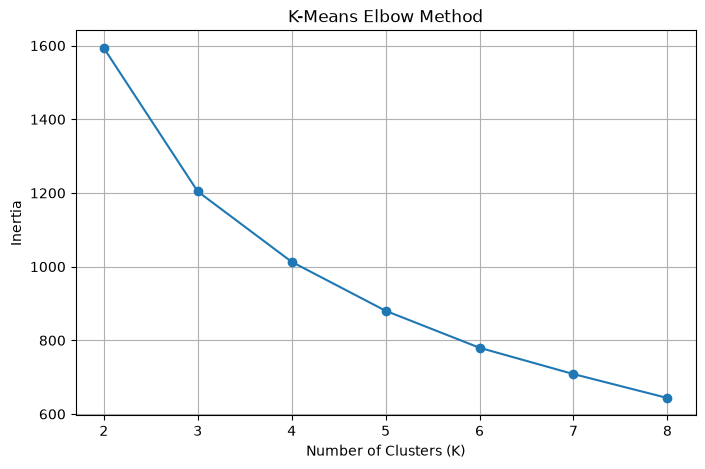

In [ ]:
#41 Plot the elbow graph

plt.figure(figsize=(8, 5))

plt.plot(range(2, 9), inertia_values, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")

plt.grid(True)
plt.show()

In [ ]:
#42 Create K-Means model with 2 clusters(task 3 completed)
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Assign each applicant to a cluster
df["customer_segment"] = final_kmeans.fit_predict(cluster_scaled)

# Display the number of applicants in each segment
print("Customer Segment Counts:")
print(df["customer_segment"].value_counts())

# Display average income and loan amount in each segment
print("\nCustomer Segment Details:")
print(df.groupby("customer_segment")[
    ["annual_income", "loan_amount", "credit_score"]
].mean().round(2))

Customer Segment Counts:
customer_segment
1    557
0    243
Name: count, dtype: int64

Customer Segment Details:
                  annual_income  loan_amount  credit_score
customer_segment                                          
0                     103277.87     46014.67        695.07
1                      52046.60     16292.99        691.92


In [46]:
#43 Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Store all four trained models
classification_models = {
    "Logistic Regression": full_pipeline,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": random_forest_pipeline
}

# Add XGBoost model with preprocessing
classification_models["XGBoost"] = None

# Evaluate the first three pipeline models
for name, model in classification_models.items():

    if name == "XGBoost":
        predictions = xgb_model.predict(X_val_processed)
    else:
        predictions = model.predict(X_val)

    print("\nModel:", name)
    print("Accuracy:", round(accuracy_score(y_val, predictions), 3))
    print("Precision:", round(precision_score(y_val, predictions), 3))
    print("Recall:", round(recall_score(y_val, predictions), 3))
    print("F1 Score:", round(f1_score(y_val, predictions), 3))
    print("Confusion Matrix:")
    print(confusion_matrix(y_val, predictions))


Model: Logistic Regression
Accuracy: 0.675
Precision: 0.421
Recall: 0.163
F1 Score: 0.235
Confusion Matrix:
[[100  11]
 [ 41   8]]

Model: Decision Tree
Accuracy: 0.669
Precision: 0.4
Recall: 0.163
F1 Score: 0.232
Confusion Matrix:
[[99 12]
 [41  8]]

Model: Random Forest
Accuracy: 0.675
Precision: 0.412
Recall: 0.143
F1 Score: 0.212
Confusion Matrix:
[[101  10]
 [ 42   7]]

Model: XGBoost
Accuracy: 0.688
Precision: 0.455
Recall: 0.102
F1 Score: 0.167
Confusion Matrix:
[[105   6]
 [ 44   5]]


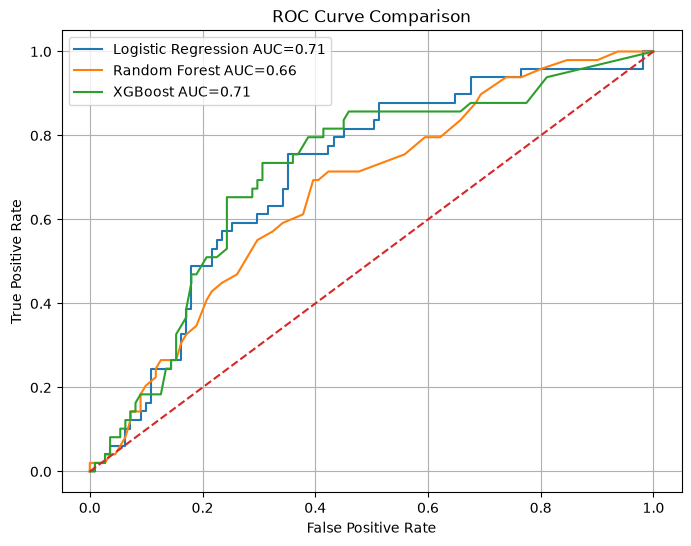

In [47]:
#44 Import ROC curve and AUC
from sklearn.metrics import roc_curve, auc

# Get prediction probabilities from three models
lr_probabilities = full_pipeline.predict_proba(X_val)[:, 1]

rf_probabilities = random_forest_pipeline.predict_proba(X_val)[:, 1]

xgb_probabilities = xgb_model.predict_proba(X_val_processed)[:, 1]

# Calculate ROC values
lr_fpr, lr_tpr, _ = roc_curve(y_val, lr_probabilities)
rf_fpr, rf_tpr, _ = roc_curve(y_val, rf_probabilities)
xgb_fpr, xgb_tpr, _ = roc_curve(y_val, xgb_probabilities)

# Calculate AUC
lr_auc = auc(lr_fpr, lr_tpr)
rf_auc = auc(rf_fpr, rf_tpr)
xgb_auc = auc(xgb_fpr, xgb_tpr)

# Plot all three ROC curves
plt.figure(figsize=(8, 6))

plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression AUC={lr_auc:.2f}")
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest AUC={rf_auc:.2f}")
plt.plot(xgb_fpr, xgb_tpr, label=f"XGBoost AUC={xgb_auc:.2f}")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [48]:
#45 Import precision and recall tools
from sklearn.metrics import precision_recall_curve

# Get prediction probabilities
probabilities = full_pipeline.predict_proba(X_val)[:, 1]

# Calculate precision and recall at different thresholds
precisions, recalls, thresholds = precision_recall_curve(
    y_val, probabilities
)

# Find thresholds that achieve at least 75% recall
valid_indices = np.where(recalls[:-1] >= 0.75)[0]

if len(valid_indices) > 0:
    # Select the threshold with the highest precision
    best_index = valid_indices[
        np.argmax(precisions[valid_indices])
    ]

    best_threshold = thresholds[best_index]

    print("Selected Threshold:", round(best_threshold, 3))
    print("Recall:", round(recalls[best_index], 3))
    print("Precision:", round(precisions[best_index], 3))
else:
    print("No threshold achieved 75% recall.")

Selected Threshold: 0.266
Recall: 0.755
Precision: 0.487


In [49]:
#46 Import GridSearchCV
from sklearn.model_selection import GridSearchCV

# Define parameter combinations
rf_parameters = {
    "model__n_estimators": [50, 100],
    "model__max_depth": [3, 5, None],
    "model__min_samples_split": [2, 5]
}

# Create GridSearchCV
rf_grid_search = GridSearchCV(
    random_forest_pipeline,
    param_grid=rf_parameters,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

# Train using training data
rf_grid_search.fit(X_train, y_train)

# Display best parameters and score
print("Best Random Forest Parameters:")
print(rf_grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:",
      round(rf_grid_search.best_score_, 3))

Best Random Forest Parameters:
{'model__max_depth': 5, 'model__min_samples_split': 2, 'model__n_estimators': 50}

Best Cross-Validation Accuracy: 0.715


In [ ]:
# 47 Import RandomizedSearchCV
from sklearn.model_selection import RandomizedSearchCV

# Define XGBoost parameter options
xgb_parameters = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [2, 3, 4, 5],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 1.0]
}

# Create RandomizedSearchCV
xgb_random_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        eval_metric="logloss",
        random_state=42
    ),
    param_distributions=xgb_parameters,
    n_iter=15,
    cv=3,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)

# Train using preprocessed training data
xgb_random_search.fit(X_train_processed, y_train)

# Display best parameters and score
print("Best XGBoost Parameters:")
print(xgb_random_search.best_params_)

print("\nBest Cross-Validation Accuracy:",
      round(xgb_random_search.best_score_, 3))

Best XGBoost Parameters:
{'subsample': 0.7, 'n_estimators': 200, 'max_depth': 2, 'learning_rate': 0.01}

Best Cross-Validation Accuracy: 0.715


In [ ]:
#48 Import regression evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create mean baseline predictions
baseline_predictions = np.full(
    len(y_reg_test),
    y_reg_train.mean()
)

# Store predictions from all four approaches
regression_results = {
    "Mean Baseline": baseline_predictions,
    "Linear Regression": linear_predictions,
    "Ridge": ridge_predictions,
    "Lasso": lasso_predictions
}

# Evaluate each model
for name, predictions in regression_results.items():

    mae = mean_absolute_error(y_reg_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_reg_test, predictions))
    r2 = r2_score(y_reg_test, predictions)

    print("\nModel:", name)
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 3))


Model: Mean Baseline
MAE: 14716.63
RMSE: 19798.24
R2 Score: -0.0

Model: Linear Regression
MAE: 12071.19
RMSE: 16545.06
R2 Score: 0.301

Model: Ridge
MAE: 12071.88
RMSE: 16544.42
R2 Score: 0.302

Model: Lasso
MAE: 12071.01
RMSE: 16544.68
R2 Score: 0.302


In [52]:
#49 Prepare the testing data
X_test_processed = preprocessor.transform(X_test)

# Get the best tuned XGBoost model
best_model = xgb_random_search.best_estimator_

# Evaluate on the test data for the first time
test_predictions = best_model.predict(X_test_processed)

# Calculate evaluation metrics
print("Final XGBoost Test Results")

print("Accuracy:",
      round(accuracy_score(y_test, test_predictions), 3))

print("Precision:",
      round(precision_score(y_test, test_predictions), 3))

print("Recall:",
      round(recall_score(y_test, test_predictions), 3))

print("F1 Score:",
      round(f1_score(y_test, test_predictions), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nFinal test evaluation completed!")

Final XGBoost Test Results
Accuracy: 0.675
Precision: 0.364
Recall: 0.082
F1 Score: 0.133

Confusion Matrix:
[[104   7]
 [ 45   4]]

Final test evaluation completed!
